
# SenseForge — 13 Advanced Neural WSD Training

## Objective
Train a target-aware neural word sense disambiguation classifier using frozen XLM-RoBERTa contextual embeddings.

### Architecture
XLM-RoBERTa → Target-token embeddings → Residual MLP → Lemma-restricted sense prediction

### Experiments
- Residual MLP with dropout and layer normalization
- Class-weighted cross-entropy
- AdamW optimizer and learning-rate scheduling
- Gradient clipping and early stopping
- Validation-based model selection
- Comparison with Notebook 08

### Dataset
SenseForge WSD V2:
- 506 training examples
- 60 validation examples
- 62 held-out test examples
- 6 ambiguous words and 12 senses

The held-out test set is not used during model development.


In [2]:
from pathlib import Path
import json
import random
import copy

import numpy as np
import torch

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

ART = ROOT / "artifacts"
V2 = ART / "wsd_v2"
CACHE = ART / "wsd_v2_supervised" / "embedding_cache"
OUT = ART / "wsd_v2_advanced"

OUT.mkdir(parents=True, exist_ok=True)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")

assert V2.exists(), "V2 dataset missing"
assert CACHE.exists(), "Notebook 08 embedding cache missing"

print("Project:", ROOT)
print("Device:", DEVICE)
print("Output:", OUT)

Project: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge
Device: cpu
Output: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/artifacts/wsd_v2_advanced


In [3]:
import hashlib
from collections import Counter

def load_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

train_rows = load_jsonl(V2 / "train.jsonl")
val_rows = load_jsonl(V2 / "validation.jsonl")

def load_cache(name, rows):
    path = CACHE / f"{name}_xlmr.npy"
    manifest_path = CACHE / f"{name}_manifest.json"

    manifest = json.loads(
        manifest_path.read_text(encoding="utf-8")
    )

    fingerprint = hashlib.sha256(
        json.dumps(
            rows,
            sort_keys=True,
            ensure_ascii=False
        ).encode("utf-8")
    ).hexdigest()

    assert manifest["fingerprint"] == fingerprint
    assert manifest["model"] == "xlm-roberta-base"
    assert manifest["max_length"] == 96
    assert manifest["pooling"] == "target_mean"

    return np.load(path).astype(np.float32)

X_train_raw = load_cache("train", train_rows)
X_val_raw = load_cache("validation", val_rows)

senses = sorted({r["sense_id"] for r in train_rows})
words = sorted({r["target_word"] for r in train_rows})

sense_to_id = {s: i for i, s in enumerate(senses)}

y_train = np.array([
    sense_to_id[r["sense_id"]]
    for r in train_rows
], dtype=np.int64)

y_val = np.array([
    sense_to_id[r["sense_id"]]
    for r in val_rows
], dtype=np.int64)

assert X_train_raw.shape == (506, 768)
assert X_val_raw.shape == (60, 768)
assert len(senses) == 12

print("Training:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)
print("Words:", words)
print("Senses:", senses)

Training: (506, 768)
Validation: (60, 768)
Words: ['bank', 'interest', 'plant', 'point', 'right', 'table']
Senses: ['bank.1', 'bank.2', 'interest.1', 'interest.2', 'plant.1', 'plant.2', 'point.1', 'point.2', 'right.1', 'right.2', 'table.1', 'table.2']


In [4]:
from sklearn.preprocessing import StandardScaler
import joblib

scaler = StandardScaler()

X_train = scaler.fit_transform(
    X_train_raw
).astype(np.float32)

X_val = scaler.transform(
    X_val_raw
).astype(np.float32)

joblib.dump(scaler, OUT / "scaler.joblib")

print("Train mean:", X_train.mean())
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Train mean: -4.5547686e-09
Train shape: (506, 768)
Validation shape: (60, 768)


In [5]:
word_to_classes = {}

for word in words:
    indices = [
        i for i, sense in enumerate(senses)
        if sense.startswith(word + ".")
    ]

    assert len(indices) == 2, (
        f"{word}: expected 2 senses, got {len(indices)}"
    )

    word_to_classes[word] = indices

def build_class_masks(rows):
    masks = np.zeros(
        (len(rows), len(senses)),
        dtype=bool
    )

    for i, row in enumerate(rows):
        masks[i, word_to_classes[row["target_word"]]] = True

    return masks

train_masks = build_class_masks(train_rows)
val_masks = build_class_masks(val_rows)

assert np.all(train_masks.sum(axis=1) == 2)
assert np.all(val_masks.sum(axis=1) == 2)

print("Lemma-restricted masks ready.")
print(word_to_classes)

Lemma-restricted masks ready.
{'bank': [0, 1], 'interest': [2, 3], 'plant': [4, 5], 'point': [6, 7], 'right': [8, 9], 'table': [10, 11]}


In [6]:
import torch.nn as nn

class ResidualWSDClassifier(nn.Module):
    def __init__(
        self,
        input_dim=768,
        hidden_dim=256,
        num_classes=12
    ):
        super().__init__()

        self.projection = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.3)
        )

        self.residual = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, hidden_dim)
        )

        self.norm = nn.LayerNorm(hidden_dim)

        self.classifier = nn.Linear(
            hidden_dim, num_classes
        )

    def forward(self, x):
        h = self.projection(x)
        h = self.norm(h + self.residual(h))
        return self.classifier(h)

model = ResidualWSDClassifier(
    input_dim=768,
    hidden_dim=256,
    num_classes=len(senses)
).to(DEVICE)

parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(model)
print("Trainable parameters:", parameters)

ResidualWSDClassifier(
  (projection): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.3, inplace=False)
  )
  (residual): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
  (norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
  (classifier): Linear(in_features=256, out_features=12, bias=True)
)
Trainable parameters: 332556


In [7]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight

train_ds = TensorDataset(
    torch.tensor(X_train),
    torch.tensor(y_train),
    torch.tensor(train_masks)
)

val_ds = TensorDataset(
    torch.tensor(X_val),
    torch.tensor(y_val),
    torch.tensor(val_masks)
)

train_loader = DataLoader(
    train_ds,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False
)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(senses)),
    y=y_train
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=0.01
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

EPOCHS = 40
PATIENCE = 7

print("Training configuration ready.")

Training configuration ready.


In [8]:
from sklearn.metrics import accuracy_score, f1_score

best_f1 = -1.0
best_state = None
best_epoch = None
wait = 0
history = []

for epoch in range(1, EPOCHS + 1):

    model.train()
    total_loss = 0.0

    for features, labels, masks in train_loader:
        features = features.to(DEVICE)
        labels = labels.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad()

        logits = model(features)
        logits = logits.masked_fill(~masks, -1e4)

        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        total_loss += loss.item()

    model.eval()
    predictions = []
    ground_truth = []

    with torch.no_grad():
        for features, labels, masks in val_loader:
            features = features.to(DEVICE)
            masks = masks.to(DEVICE)

            logits = model(features)
            logits = logits.masked_fill(~masks, -1e4)

            predicted = logits.argmax(dim=1).cpu().numpy()

            predictions.extend(predicted)
            ground_truth.extend(labels.numpy())

    val_accuracy = accuracy_score(
        ground_truth, predictions
    )

    val_f1 = f1_score(
        ground_truth,
        predictions,
        labels=list(range(len(senses))),
        average="macro",
        zero_division=0
    )

    train_loss = total_loss / len(train_loader)

    scheduler.step(val_f1)

    history.append({
        "epoch": epoch,
        "train_loss": float(train_loss),
        "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(val_f1)
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Loss={train_loss:.4f} | "
        f"Val Acc={val_accuracy:.4f} | "
        f"Macro-F1={val_f1:.4f}"
    )

    if val_f1 > best_f1 + 1e-5:
        best_f1 = val_f1
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    if wait >= PATIENCE:
        print("Early stopping triggered.")
        break

assert best_state is not None
model.load_state_dict(best_state)

checkpoint = {
    "model_state": best_state,
    "senses": senses,
    "architecture": "ResidualWSDClassifier",
    "hidden_dim": 256,
    "best_epoch": best_epoch,
    "best_val_macro_f1": best_f1,
    "seed": SEED
}

torch.save(
    checkpoint,
    OUT / "advanced_residual_mlp.pt"
)

(OUT / "training_history.json").write_text(
    json.dumps(history, indent=2),
    encoding="utf-8"
)

print("\nBest epoch:", best_epoch)
print("Best validation Macro-F1:", best_f1)
print("Checkpoint saved.")

Epoch 01 | Loss=0.2281 | Val Acc=0.9667 | Macro-F1=0.9667
Epoch 02 | Loss=0.0508 | Val Acc=1.0000 | Macro-F1=1.0000
Epoch 03 | Loss=0.0289 | Val Acc=0.9833 | Macro-F1=0.9603
Epoch 04 | Loss=0.0080 | Val Acc=1.0000 | Macro-F1=1.0000
Epoch 05 | Loss=0.0042 | Val Acc=0.9833 | Macro-F1=0.9603
Epoch 06 | Loss=0.0025 | Val Acc=0.9833 | Macro-F1=0.9603
Epoch 07 | Loss=0.0038 | Val Acc=1.0000 | Macro-F1=1.0000
Epoch 08 | Loss=0.0012 | Val Acc=0.9833 | Macro-F1=0.9852
Epoch 09 | Loss=0.0010 | Val Acc=1.0000 | Macro-F1=1.0000
Early stopping triggered.

Best epoch: 2
Best validation Macro-F1: 1.0
Checkpoint saved.


In [9]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score
)

model.eval()

with torch.no_grad():
    features = torch.tensor(X_val).to(DEVICE)
    masks = torch.tensor(val_masks).to(DEVICE)

    logits = model(features)
    logits = logits.masked_fill(~masks, -1e4)

    val_predictions = logits.argmax(dim=1).cpu().numpy()

print("=== VALIDATION RESULTS ===")

print("Accuracy:", accuracy_score(y_val, val_predictions))

print("Macro Precision:", precision_score(
    y_val, val_predictions,
    labels=list(range(len(senses))),
    average="macro",
    zero_division=0
))

print("Macro Recall:", recall_score(
    y_val, val_predictions,
    labels=list(range(len(senses))),
    average="macro",
    zero_division=0
))

print("Macro-F1:", f1_score(
    y_val, val_predictions,
    labels=list(range(len(senses))),
    average="macro",
    zero_division=0
))

print("\nClassification report:")
print(classification_report(
    y_val, val_predictions,
    labels=list(range(len(senses))),
    target_names=senses,
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_val, val_predictions,
    labels=list(range(len(senses)))
))

=== VALIDATION RESULTS ===
Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro-F1: 1.0

Classification report:
              precision    recall  f1-score   support

      bank.1       1.00      1.00      1.00         4
      bank.2       1.00      1.00      1.00         1
  interest.1       1.00      1.00      1.00         3
  interest.2       1.00      1.00      1.00         2
     plant.1       1.00      1.00      1.00         4
     plant.2       1.00      1.00      1.00        14
     point.1       1.00      1.00      1.00        11
     point.2       1.00      1.00      1.00         2
     right.1       1.00      1.00      1.00         3
     right.2       1.00      1.00      1.00         5
     table.1       1.00      1.00      1.00         2
     table.2       1.00      1.00      1.00         9

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60


Confusion matr

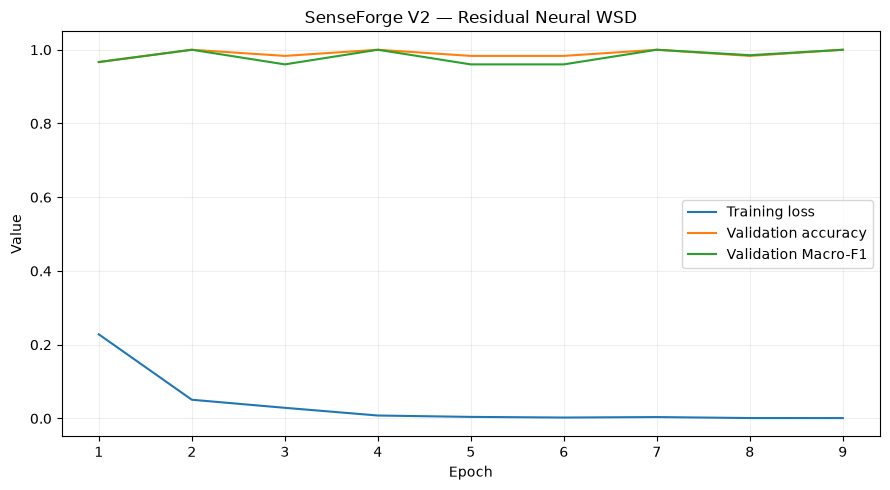

In [10]:
import matplotlib.pyplot as plt

epochs = [r["epoch"] for r in history]
losses = [r["train_loss"] for r in history]
accuracies = [r["val_accuracy"] for r in history]
f1_values = [r["val_macro_f1"] for r in history]

plt.figure(figsize=(9, 5))

plt.plot(epochs, losses, label="Training loss")
plt.plot(epochs, accuracies, label="Validation accuracy")
plt.plot(epochs, f1_values, label="Validation Macro-F1")

plt.xlabel("Epoch")
plt.ylabel("Value")
plt.title("SenseForge V2 — Residual Neural WSD")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    OUT / "advanced_training_curves.png",
    dpi=180
)

plt.show()